# Tremor and the medication effect under the 90% accuracy screen

`2.32` found that tremor severity OFF medication correlates with each participant's medication effect on
prior use (Spearman rho = 0.57, p = 0.009, n = 20, at the default 60% screen). This notebook repeats the
analysis with only the patients who reach at least 90% accuracy on 100%-coherence trials in **both**
sessions (`catalog.load_trials(min_easy_accuracy=0.9)`), to see whether the correlation holds or
strengthens among patients who clearly performed the task.

**Two versions of the outcome.**

1. **60% effects, 90% patients.** The reported posterior from `2.26`, restricted to the patients who pass
   90%. This isolates what dropping patients does.
2. **Refitted at 90%.** The reported model (`mcmc_cache.sample_model`, same priors, settings and seed)
   fitted to the 90% sample only, per subtype as in `2.26`. This is what a 90% analysis would report,
   because partial pooling now draws only on the retained patients.

**Read this as a sensitivity analysis.** The 90% threshold already exists in the project, but choosing to
look at it after seeing a correlation is still a choice made after the fact. Section 1 shows exactly who
the screen removes, and that decides most of the answer.

Fits are cached in the gitignored `outputs/` directory, never in `processed/`.

| File | Contents |
|---|---|
| `medication_response_accu90_effects.csv` | participant effects, 60% and refitted at 90% |
| `medication_response_accu90_tremor.csv` | tremor correlation under each screen and outcome |
| `medication_response_accu90_planned.csv` | tremor and bradykinesia, the planned pair, Holm-corrected |
| `medication_response_accu90_moderators.csv` | hierarchical moderator models at 90% |
| `medication_response_accu90_screen.csv` | clinical and motor phenotype screen at 90% |
| `medication_response_accu90_tremor.pdf/.png` | figure |

In [1]:
%matplotlib inline
%reload_ext autoreload
%autoreload 2
from imports import *
from statsmodels.stats.multitest import multipletests

from src.data_io import cache, catalog
from src.utils import classification_utils
from src.utils.mcmc_cache import FIT_SETTINGS, TERMS, build_design, ess_bulk, prepare_trials, rhat, sample_model

In [2]:
SCREEN = 0.9
metadata_60 = catalog.load_metadata()
metadata_90 = catalog.load_metadata(min_easy_accuracy=SCREEN)
trials_90 = catalog.load_trials(min_easy_accuracy=SCREEN)
effects_60 = catalog.load("participant_medication_effects").set_index("participant_id")
dose = catalog.read(catalog.output_path("medication_dose_table.csv")).set_index("participant")
subjects_map_90, _ = classification_utils.get_subject_classification_ids(metadata_90)

SUBTYPES = {"tremor": "tremor_dominant", "bradykinetic": "bradykinesia_dominant"}
COL_MED = TERMS.index("col:med")
SUBTYPE_COLOR = {"tremor": "#2a78d6", "bradykinetic": "#eb6834"}   # reference palette slots 1-2
SUBTYPE_LABEL = {"tremor": "Tremor dominant", "bradykinetic": "Bradykinesia dominant"}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#d9d8d4"
rng = np.random.default_rng(0)

PD subjects with ON+OFF sessions: 29
PD subjects with UPDRS subtype: 17
All PD subjects:           29
  Tremor dominant:         7 	 ['P6' 'P11' 'P12' 'P17' 'P18' 'P29' 'P32']
  Brady dominant:          9 	 ['P1' 'P4' 'P9' 'P13' 'P20' 'P22' 'P23' 'P28' 'P34']
  Intermediate:            1 	 ['P24']
HC subjects:               13 	 ['HC1' 'HC3' 'HC6' 'HC7' 'HC13' 'AV' 'EM' 'ES' 'GF' 'GP' 'JA' 'MRM' 'SY']


## 1. Who the 90% screen removes

A patient is kept only if both sessions reach 90%. Each removed patient's session accuracies, OFF tremor
score and 60% medication effect are below.

In [3]:
def phenotypes(metadata):
    """One row per subtyped PD patient: OFF-session clinical and motor phenotypes."""
    md_ = metadata[(metadata["is_pd"] != 0) & metadata["trem_vs_brady_type"].isin(["tremor", "bradykinetic"])]
    off = md_[md_["treatment"] == "OFF"].set_index("subject_id")
    on = md_[md_["treatment"] == "ON"].set_index("subject_id")
    table = pd.DataFrame({
        "subtype": off["trem_vs_brady_type"],
        "acc_off": off["easy_accuracy_pct"], "acc_on": on["easy_accuracy_pct"],
        "age": off["age"], "male": (off["gender"] == "M").astype(float), "years_since_diagnosis": off["years_since_diagnosis"],
        "MoCA": md_.groupby("subject_id")["MoCA"].mean(), "hoehn_yahr": md_.groupby("subject_id")["Hoehn_and_Yahr_Stage"].max(),
        "washout_h": off["off_meds_hrs"], "explicit_off": off["explicitness"],
        "UPDRS_off": off["UPDRS"], "tremor_off": off["tremor_score"], "brady_off": off["bradykinesia_score"],
        "pigd_off": off["pigd_score"], "trem_by_brady_off": off["trem_by_brady"],
        "UPDRS_improvement": off["UPDRS_improvement"], "tremor_improvement": off["tremor_improvement"],
        "bradykinesia_improvement": off["bradykinesia_improvement"],
    })
    table["LEDD"] = dose["LEDD (mg/day)"]
    table["controlled_release"] = dose["formulation"].str.contains("CR").astype(float)
    table["subtype_td"] = (table["subtype"] == "tremor").astype(float)
    return table


pheno_60 = phenotypes(metadata_60).loc[effects_60.index]
kept = [s for s in pheno_60.index if s in set(metadata_90["subject_id"])]
removed = pheno_60.drop(kept)
print(f"60% screen: {len(pheno_60)} patients; 90% screen: {len(kept)} "
      f"({pheno_60.loc[kept, 'subtype'].value_counts().to_dict()})")
removed[["subtype", "acc_off", "acc_on", "tremor_off"]].join(effects_60[["mean", "interval"]]).round(2)

60% screen: 20 patients; 90% screen: 16 ({'bradykinetic': 9, 'tremor': 7})


,subtype,acc_off,acc_on,tremor_off,mean,interval
participant_id,,,,,,
P19,tremor,90.57,86.36,0.64,0.29,includes 0
P31,tremor,97.50,87.42,0.73,-0.92,below 0
P7,tremor,64.97,94.90,0.73,-0.04,includes 0
P33,bradykinetic,96.88,85.00,0.09,-0.26,includes 0


## 2. Refit the reported model on the 90% sample

Per subtype, as in `2.26`. The draws are cached under `outputs/medication_response_accu90_mcmc/` with a
fingerprint of the exact design matrix, so a rerun loads them unless the data change.

In [4]:
def fit_or_load_90(subtype, subset):
    design, outcomes, subject_index, subjects = build_design(subset)
    fingerprint = cache.fingerprint(design, outcomes, subject_index)
    draws_path = catalog.output_path(f"medication_response_accu90_mcmc/{subtype}.npz")
    meta_path = draws_path.with_suffix(".json")
    meta = cache.read_sidecar(meta_path)
    if meta and meta["fingerprint"] == fingerprint and meta["settings"] == FIT_SETTINGS and draws_path.exists():
        print(f"{subtype}: loaded cached draws")
        return cache.load_arrays(draws_path)
    print(f"{subtype}: sampling ({len(subjects)} participants, {len(subset):,} trials)")
    idata = sample_model(subset, **FIT_SETTINGS)
    arrays = {"beta": idata.posterior["beta"].values, "sd_u": idata.posterior["sd_u"].values,
              "z_u": idata.posterior["z_u"].values, "diverging": idata.sample_stats["diverging"].values,
              "subjects": np.asarray(subjects, dtype=str)}
    cache.save_arrays(draws_path, **arrays)
    cache.write_sidecar(meta_path, {"fingerprint": fingerprint, "settings": FIT_SETTINGS, "min_easy_accuracy": SCREEN,
                                    "subjects": list(map(str, subjects)), "n_trials": int(len(subset))})
    return arrays


fits_90, rows, pop_rows = {}, [], []
for subtype, key in SUBTYPES.items():
    subset = prepare_trials(trials_90, subjects_map_90[key])
    fit = fits_90[subtype] = fit_or_load_90(subtype, subset)
    beta, sd, z = fit["beta"][..., COL_MED], fit["sd_u"][..., COL_MED], fit["z_u"][..., COL_MED]
    effects = beta[..., None] + z * sd[..., None]                       # (chain, draw, participant)
    flat = effects.reshape(-1, effects.shape[-1])
    for j, pid in enumerate(fit["subjects"]):
        low, high = np.percentile(flat[:, j], [2.5, 97.5])
        rows.append({"participant_id": pid, "subtype": subtype, "effect_90": flat[:, j].mean(), "low_90": low, "high_90": high,
                     "r_hat": rhat(effects[..., j])})
    pop = beta.ravel()
    pop_rows.append({"subtype": subtype, "screen": "90%", "participants": len(fit["subjects"]), "col:med": pop.mean(),
                     "2.5%": np.percentile(pop, 2.5), "97.5%": np.percentile(pop, 97.5), "P(> 0)": (pop > 0).mean(),
                     "between-participant SD": sd.mean(), "divergences": int(fit["diverging"].sum()),
                     "max r_hat (beta)": max(rhat(fit["beta"][..., i]) for i in range(len(TERMS)))})
effects_90 = pd.DataFrame(rows).set_index("participant_id")
population = pd.DataFrame(pop_rows)
population.round(3)

tremor: loaded cached draws
bradykinetic: loaded cached draws


,subtype,screen,participants,col:med,2.5%,97.5%,P(> 0),between-participant SD,divergences,max r_hat (beta)
0,tremor,90%,7,0.912,0.264,1.577,0.992,0.755,0,1.004
1,bradykinetic,90%,9,0.114,-0.485,0.715,0.662,0.831,0,1.004


In [5]:
from src.utils.mcmc_cache import cached_draws
for subtype in SUBTYPES:
    a = cached_draws(subtype)
    pop = a["beta"][..., COL_MED].ravel()
    population.loc[len(population)] = {"subtype": subtype, "screen": "60% (reported)", "participants": len(a["subjects"]),
                                       "col:med": pop.mean(), "2.5%": np.percentile(pop, 2.5), "97.5%": np.percentile(pop, 97.5),
                                       "P(> 0)": (pop > 0).mean(), "between-participant SD": a["sd_u"][..., COL_MED].mean(),
                                       "divergences": int(a["diverging"].sum()), "max r_hat (beta)": np.nan}
population.sort_values(["subtype", "screen"]).round(3)

,subtype,screen,participants,col:med,2.5%,97.5%,P(> 0),between-participant SD,divergences,max r_hat (beta)
3,bradykinetic,60% (reported),10,0.071,-0.447,0.597,0.609,0.789,0,NaN
1,bradykinetic,90%,9,0.114,-0.485,0.715,0.662,0.831,0,1.004
2,tremor,60% (reported),10,0.532,-0.079,1.131,0.959,0.912,0,NaN
0,tremor,90%,7,0.912,0.264,1.577,0.992,0.755,0,1.004


## 3. Do the retained patients' effects change when refitted?

In [6]:
compare = effects_60.loc[kept, ["mean", "2.5%", "97.5%"]].rename(columns={"mean": "effect_60", "2.5%": "low_60", "97.5%": "high_60"})
compare = compare.join(effects_90.drop(columns="subtype")).join(pheno_60.loc[kept])
compare["group_90"] = np.select([compare["low_90"] > 0, compare["high_90"] < 0], ["increase", "decrease"], "no change")
r = stats.pearsonr(compare["effect_60"], compare["effect_90"])[0]
print(f"retained patients: r(60% effect, 90% effect) = {r:.3f}; mean |difference| = {(compare['effect_90'] - compare['effect_60']).abs().mean():.3f}")
compare[["subtype", "effect_60", "effect_90", "low_90", "high_90", "group_90", "tremor_off"]].sort_values("effect_90").round(2)

retained patients: r(60% effect, 90% effect) = 0.999; mean |difference| = 0.030


,subtype,effect_60,effect_90,low_90,high_90,group_90,tremor_off
participant_id,,,,,,,
P22,bradykinetic,-1.04,-1.06,-1.58,-0.55,decrease,0.09
P23,bradykinetic,-0.65,-0.65,-1.20,-0.15,decrease,0.18
P4,bradykinetic,-0.33,-0.33,-0.84,0.18,no change,0.40
P13,bradykinetic,0.01,-0.00,-0.51,0.50,no change,0.27
P18,tremor,0.04,0.14,-0.41,0.70,no change,0.55
P20,bradykinetic,0.19,0.20,-0.32,0.73,no change,0.64
P34,bradykinetic,0.28,0.29,-0.20,0.79,no change,0.64
P11,tremor,0.38,0.46,-0.14,1.04,no change,1.00
P32,tremor,0.38,0.46,-0.05,0.99,no change,1.18


## 4. The tremor correlation under each screen

Spearman rho with a percentile bootstrap 95% interval (10,000 resamples) and a permutation p-value
(20,000 permutations); Pearson r with its Fisher interval; rho within each subtype; and the partial
correlation controlling for subtype. The 60% rows are the `2.32` result and the same result without P31,
for reference.

In [7]:
def correlation_row(label, effect, table):
    x, y = table["tremor_off"].to_numpy(), effect.loc[table.index].to_numpy()
    rho = stats.spearmanr(x, y)[0]
    boot = []
    for _ in range(10000):
        i = rng.integers(0, len(x), len(x))
        if np.ptp(x[i]) > 0 and np.ptp(y[i]) > 0:
            boot.append(stats.spearmanr(x[i], y[i])[0])
    rx, ry = stats.rankdata(x), stats.rankdata(y)
    perm = np.array([np.corrcoef(rx, rng.permutation(ry))[0, 1] for _ in range(20000)])
    pearson = stats.pearsonr(x, y)
    ci = pearson.confidence_interval()
    resid = lambda v: smf.ols("v ~ subtype", data=table.assign(v=v)).fit().resid
    partial = stats.pearsonr(resid(x), resid(y))
    within = {f"rho within {s}": stats.spearmanr(g["tremor_off"], effect.loc[g.index])[0] for s, g in table.groupby("subtype")}
    return {"sample": label, "n": len(x), "Spearman rho": rho, "rho 2.5%": np.percentile(boot, 2.5), "rho 97.5%": np.percentile(boot, 97.5),
            "p (perm)": (np.abs(perm) >= abs(rho) - 1e-12).mean(), "Pearson r": pearson[0], "r 2.5%": ci.low, "r 97.5%": ci.high,
            "Pearson p": pearson[1], "R2": pearson[0] ** 2, **within, "partial r (subtype)": partial[0], "partial p": partial[1]}


e60, e90 = effects_60["mean"], effects_90["effect_90"]
tremor_table = pd.DataFrame([
    correlation_row("60% screen, all 20 (2.32)", e60, pheno_60),
    correlation_row("60% screen, without P31", e60, pheno_60.drop("P31")),
    correlation_row("90% screen, 60% effects", e60, pheno_60.loc[kept]),
    correlation_row("90% screen, refitted effects", e90, pheno_60.loc[kept]),
]).set_index("sample")
tremor_table.round(3).T

sample,"60% screen, all 20 (2.32)","60% screen, without P31","90% screen, 60% effects","90% screen, refitted effects"
n,20.000,19.000,16.000,16.000
Spearman rho,0.566,0.628,0.588,0.588
rho 2.5%,0.121,0.204,0.099,0.114
rho 97.5%,0.845,0.887,0.927,0.922
p (perm),0.011,0.005,0.017,0.019
Pearson r,0.484,0.557,0.546,0.567
r 2.5%,0.053,0.138,0.069,0.100
r 97.5%,0.763,0.807,0.820,0.830
Pearson p,0.030,0.013,0.029,0.022
R2,0.235,0.310,0.298,0.322


**The planned pair.** The starting hypothesis was tremor versus bradykinesia, so the two component scores
form the natural family. Holm correction over those two tests, under each screen.

In [8]:
planned_rows = []
for label, effect, table in [("60% screen, all 20", e60, pheno_60), ("90% screen, refitted effects", e90, pheno_60.loc[kept])]:
    ps = []
    for var in ["tremor_off", "brady_off"]:
        x, y = table[var].to_numpy(), effect.loc[table.index].to_numpy()
        rho = stats.spearmanr(x, y)[0]
        rx, ry = stats.rankdata(x), stats.rankdata(y)
        perm = np.array([np.corrcoef(rx, rng.permutation(ry))[0, 1] for _ in range(20000)])
        ps.append((var, rho, (np.abs(perm) >= abs(rho) - 1e-12).mean()))
    holm = multipletests([p for _, _, p in ps], method="holm")[1]
    for (var, rho, p), h in zip(ps, holm):
        planned_rows.append({"sample": label, "phenotype": var, "n": len(table), "Spearman rho": rho, "p (perm)": p, "Holm p": h})
planned = pd.DataFrame(planned_rows)
planned.round(3)

,sample,phenotype,n,Spearman rho,p (perm),Holm p
0,"60% screen, all 20",tremor_off,20,0.566,0.009,0.019
1,"60% screen, all 20",brady_off,20,0.238,0.307,0.307
2,"90% screen, refitted effects",tremor_off,16,0.588,0.019,0.038
3,"90% screen, refitted effects",brady_off,16,-0.003,0.992,0.992


saved medication_response_accu90_tremor.pdf, medication_response_accu90_tremor.png


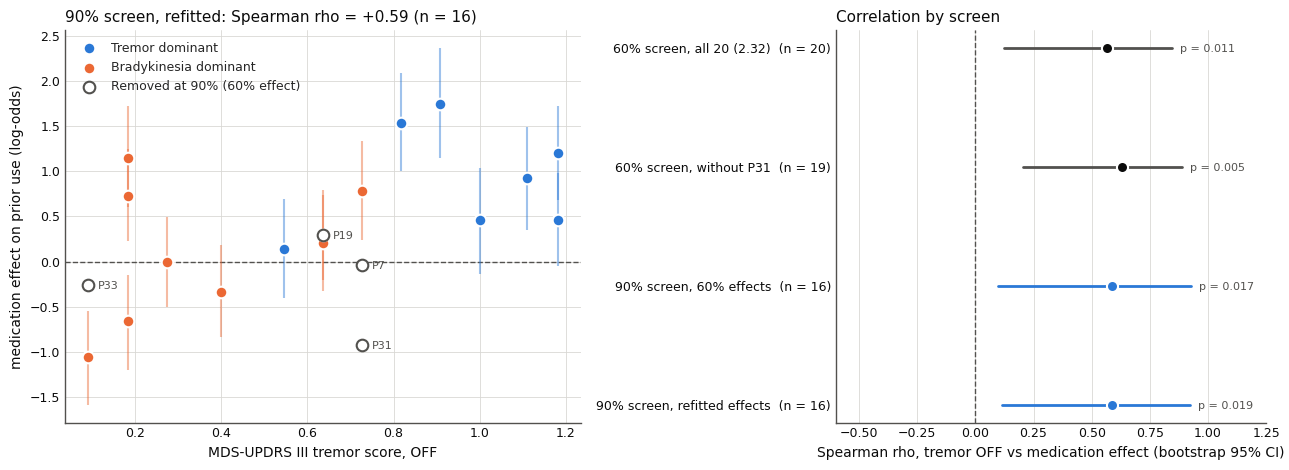

In [9]:
def style(ax):
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    for side in ["left", "bottom"]:
        ax.spines[side].set_color(MUTED)
    ax.tick_params(colors=MUTED, labelcolor=INK, labelsize=9)
    ax.grid(color=GRID, lw=0.6, zorder=0)
    ax.set_axisbelow(True)


fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.2, 1]})
ax = axes[0]
style(ax)
for subtype in ["tremor", "bradykinetic"]:
    g = compare[compare["subtype"] == subtype]
    ax.errorbar(g["tremor_off"], g["effect_90"], yerr=[g["effect_90"] - g["low_90"], g["high_90"] - g["effect_90"]],
                ls="", color=SUBTYPE_COLOR[subtype], alpha=0.45, lw=1.5, zorder=2)
    ax.scatter(g["tremor_off"], g["effect_90"], s=70, color=SUBTYPE_COLOR[subtype], edgecolor="white", linewidth=1.5,
               zorder=3, label=SUBTYPE_LABEL[subtype])
gone = removed.join(effects_60["mean"])
ax.scatter(gone["tremor_off"], gone["mean"], s=70, facecolor="white", edgecolor=MUTED, linewidth=1.5, zorder=3,
           label="Removed at 90% (60% effect)")
for pid, row in gone.iterrows():
    ax.annotate(pid, (row["tremor_off"], row["mean"]), xytext=(7, -3), textcoords="offset points", fontsize=8, color=MUTED)
ax.axhline(0, color=MUTED, lw=1, ls="--", zorder=1)
row = tremor_table.loc["90% screen, refitted effects"]
ax.set_xlabel("MDS-UPDRS III tremor score, OFF", color=INK, fontsize=10)
ax.set_ylabel("medication effect on prior use (log-odds)", color=INK, fontsize=10)
ax.set_title(f"90% screen, refitted: Spearman rho = {row['Spearman rho']:+.2f} (n = {int(row['n'])})", fontsize=11, color=INK, loc="left")
ax.legend(frameon=False, fontsize=9, loc="upper left")

ax = axes[1]
style(ax)
ax.grid(axis="y", visible=False)
for i, (label, r_) in enumerate(tremor_table.iterrows()):
    highlight = label.startswith("90%")
    color = SUBTYPE_COLOR["tremor"] if highlight else MUTED
    ax.plot([r_["rho 2.5%"], r_["rho 97.5%"]], [i, i], color=color, lw=2, solid_capstyle="round", zorder=2)
    ax.scatter(r_["Spearman rho"], i, s=64, color=color if highlight else INK, edgecolor="white", linewidth=1.5, zorder=3)
    ax.annotate(f"p = {r_['p (perm)']:.3f}", (r_["rho 97.5%"], i), xytext=(6, -3), textcoords="offset points", fontsize=8, color=MUTED)
ax.axvline(0, color=MUTED, lw=1, ls="--", zorder=1)
ax.set_yticks(range(len(tremor_table)))
ax.set_yticklabels([f"{s}  (n = {int(n)})" for s, n in zip(tremor_table.index, tremor_table["n"])], fontsize=9, color=INK)
ax.invert_yaxis()
ax.set_xlim(-0.6, 1.25)
ax.set_xlabel("Spearman rho, tremor OFF vs medication effect (bootstrap 95% CI)", color=INK, fontsize=10)
ax.set_title("Correlation by screen", fontsize=11, color=INK, loc="left")
fig.tight_layout()
catalog.save_figure(fig, "medication_response_accu90_tremor")
plt.show()

## 5. Hierarchical moderator models at 90%

As in `2.32`: the reported model fitted to all retained patients together, with a standardised phenotype
entered with its colour, medication and colour x medication interactions. The coefficient on
`phenotype:col:med` is the change in the medication effect per SD of the phenotype. Fitted without a
moderator, with tremor, and with bradykinesia. Cached under `outputs/medication_response_accu90_moderators/`.

In [10]:
pheno_90 = pheno_60.loc[kept]


def standardised(names):
    return {n: ((pheno_90[n] - pheno_90[n].mean()) / pheno_90[n].std(ddof=1)).to_dict() for n in names}


def signature(names):
    return {n: {k: round(v, 6) for k, v in values.items()} for n, values in standardised(names).items()}


def fit_moderators(names, subset):
    import pymc as pm

    design, outcomes, subject_index, subjects = build_design(subset)
    col, med = subset["col"].to_numpy(), subset["med"].to_numpy()
    columns, terms = [], []
    for n, values in standardised(names).items():
        s = subset["subject_id"].map(values).to_numpy()
        columns += [s, s * col, s * med, s * col * med]
        terms += [n, f"{n}:col", f"{n}:med", f"{n}:col:med"]
    with pm.Model():
        beta = pm.Normal("beta", 0, 2.5, shape=design.shape[1])
        gamma = pm.Normal("gamma", 0, 2.5, shape=len(columns)) if columns else None
        sd_u = pm.HalfNormal("sd_u", 1.0, shape=design.shape[1])
        z_u = pm.Normal("z_u", 0, 1, shape=(len(subjects), design.shape[1]))
        eta = pm.math.sum(design * (beta + (z_u * sd_u)[subject_index]), axis=1)
        if columns:
            eta = eta + pm.math.dot(np.column_stack(columns), gamma)
        pm.Bernoulli("obs", logit_p=eta, observed=outcomes)
        idata = pm.sample(FIT_SETTINGS["draws"], tune=FIT_SETTINGS["tune"], chains=FIT_SETTINGS["chains"],
                          cores=FIT_SETTINGS["chains"], target_accept=FIT_SETTINGS["target_accept"],
                          random_seed=FIT_SETTINGS["seed"], progressbar=False)
    b, sd = idata.posterior["beta"].values, idata.posterior["sd_u"].values
    out = {"fit": "+".join(names) or "none", "settings": FIT_SETTINGS, "scores": signature(names),
           "col:med mean": float(b[..., COL_MED].mean()), "sd_u col:med": float(sd[..., COL_MED].mean()),
           "sd_u col:med 2.5%": float(np.percentile(sd[..., COL_MED], 2.5)),
           "sd_u col:med 97.5%": float(np.percentile(sd[..., COL_MED], 97.5)),
           "divergences": int(idata.sample_stats["diverging"].values.sum()),
           "max r_hat (beta)": float(max(rhat(b[..., i]) for i in range(b.shape[-1])))}
    if columns:
        g = idata.posterior["gamma"].values
        for n in names:
            d = g[..., terms.index(f"{n}:col:med")]
            out[n] = {"mean": float(d.mean()), "2.5%": float(np.percentile(d, 2.5)), "97.5%": float(np.percentile(d, 97.5)),
                      "P(> 0)": float((d > 0).mean()), "r_hat": float(rhat(d)), "ess_bulk": float(ess_bulk(d))}
    return out


subset_90 = prepare_trials(trials_90, kept)
moderator_fits = {}
for spec in ["none", "tremor_off", "brady_off"]:
    names = [] if spec == "none" else spec.split("+")
    file = catalog.output_path(f"medication_response_accu90_moderators/{spec}.json")
    cached = catalog.read(file) if file.exists() else None
    if cached and cached["settings"] == FIT_SETTINGS and cached["scores"] == signature(names):
        moderator_fits[spec] = cached
        continue
    print(f"{spec}: sampling")
    moderator_fits[spec] = fit_moderators(names, subset_90)
    catalog.write(moderator_fits[spec], file)

reference_sd = moderator_fits["none"]["sd_u col:med"]
moderators = pd.DataFrame([
    {"moderator": n, **{k: fit[n][k] for k in ["mean", "2.5%", "97.5%", "P(> 0)", "r_hat", "ess_bulk"]},
     "sd_u col:med": fit["sd_u col:med"], "heterogeneity explained": 1 - (fit["sd_u col:med"] / reference_sd) ** 2,
     "divergences": fit["divergences"]}
    for n, fit in moderator_fits.items() if n != "none"
]).set_index("moderator")
print(f"no moderator: between-participant SD of col:med {reference_sd:.3f} "
      f"[{moderator_fits['none']['sd_u col:med 2.5%']:.2f}, {moderator_fits['none']['sd_u col:med 97.5%']:.2f}], "
      f"divergences {moderator_fits['none']['divergences']}")
moderators.round(3)

no moderator: between-participant SD of col:med 0.842 [0.57, 1.25], divergences 0


,mean,2.5%,97.5%,P(> 0),r_hat,ess_bulk,sd_u col:med,heterogeneity explained,divergences
moderator,,,,,,,,,
tremor_off,0.437,0.016,0.863,0.979,1.001,2254.244,0.737,0.233,0
brady_off,-0.032,-0.540,0.435,0.448,1.001,2399.262,0.872,-0.074,0


## 6. Other clinical and motor phenotypes at 90%

The clinical and motor part of the `2.32` screen, repeated on the refitted 90% effects, so the tremor
result can be read against everything else tested. Benjamini-Hochberg q across the phenotypes that
still vary in this sample.

In [11]:
SCREEN_VARS = {"age": "Age", "male": "Male sex", "years_since_diagnosis": "Years since diagnosis", "MoCA": "MoCA",
               "hoehn_yahr": "Hoehn & Yahr stage", "washout_h": "OFF washout (h)", "LEDD": "LEDD (mg/day)",
               "controlled_release": "Controlled-release levodopa", "explicit_off": "Explicit awareness, OFF",
               "UPDRS_off": "UPDRS III total", "tremor_off": "Tremor score", "brady_off": "Bradykinesia score",
               "pigd_off": "PIGD score", "trem_by_brady_off": "Tremor / bradykinesia ratio",
               "UPDRS_improvement": "Motor response to levodopa (%)", "tremor_improvement": "Tremor response (%)",
               "bradykinesia_improvement": "Bradykinesia response (%)"}
rows = []
y_all = e90.loc[pheno_90.index].to_numpy()
for var, label in SCREEN_VARS.items():
    x = pheno_90[var].astype(float).to_numpy()
    ok = ~np.isnan(x)
    if np.ptp(x[ok]) == 0:   # no variation left in this sample: not testable
        rows.append({"phenotype": label, "n": int(ok.sum()), "Spearman rho": np.nan, "p (perm)": np.nan,
                     "note": f"constant ({x[ok][0]:g})"})
        continue
    rho = stats.spearmanr(x[ok], y_all[ok])[0]
    rx, ry = stats.rankdata(x[ok]), stats.rankdata(y_all[ok])
    perm = np.array([np.corrcoef(rx, rng.permutation(ry))[0, 1] for _ in range(10000)])
    rows.append({"phenotype": label, "n": int(ok.sum()), "Spearman rho": rho, "p (perm)": (np.abs(perm) >= abs(rho) - 1e-12).mean()})
screen_90 = pd.DataFrame(rows).set_index("phenotype")
testable = screen_90["p (perm)"].notna()
screen_90.loc[testable, "q (BH)"] = multipletests(screen_90.loc[testable, "p (perm)"], method="fdr_bh")[1]
screen_90.sort_values("p (perm)").round(3)

,n,Spearman rho,p (perm),note,q (BH)
phenotype,,,,,
Tremor score,16,0.588,0.018,NaN,0.288
Tremor / bradykinesia ratio,16,0.424,0.100,NaN,0.785
Bradykinesia response (%),16,-0.294,0.267,NaN,0.785
Tremor response (%),16,-0.263,0.331,NaN,0.785
PIGD score,16,0.254,0.346,NaN,0.785
Controlled-release levodopa,16,-0.219,0.444,NaN,0.785
MoCA,16,-0.181,0.496,NaN,0.785
Motor response to levodopa (%),16,-0.174,0.513,NaN,0.785
OFF washout (h),16,-0.172,0.533,NaN,0.785


## Results and interpretation

Values are from this run. The fits are cached, so they are stable across reruns.

### Short answer

The 90% screen does not improve the tremor correlation. Its strength is essentially unchanged, its p-value
is slightly larger because there are four fewer patients, and the part of it that holds within each
subtype gets weaker, not stronger.

### Who leaves

Four patients: P7 (OFF session 65%), P19 (ON 86%), P31 (ON 87%) and P33 (ON 85%). Three of the four fail
on their ON session. That leaves 7 tremor-dominant and 9 bradykinesia-dominant patients. Refitting the
model on those 16 barely moves their effects (r = 0.999 with the 60% estimates, mean absolute change
0.03), so the two 90% versions of the outcome agree.

### The tremor correlation

| | 60% screen, n = 20 | 90% screen, refitted, n = 16 |
|---|---|---|
| Spearman rho [bootstrap 95% CI] | +0.57 [0.12, 0.85] | +0.59 [0.11, 0.92] |
| Permutation p | 0.011 | 0.019 |
| Pearson r, p | +0.48, 0.030 | +0.57, 0.022 |
| rho within tremor-dominant | +0.59 (n = 10) | +0.07 (n = 7) |
| rho within bradykinesia-dominant | +0.45 (n = 10) | +0.38 (n = 9) |
| Partial r controlling for subtype | +0.40, p = 0.08 | +0.27, p = 0.31 |
| Holm p, tremor and bradykinesia as the planned pair | 0.019 | 0.038 |
| Moderator in hierarchical model, per SD [95% CI] | +0.39 [0.03, 0.76] | +0.44 [0.02, 0.86] |
| Heterogeneity explained by tremor | 19% | 23% |

Removing P31, the high-tremor patient whose prior use fell, helps the correlation. Removing P33, a
low-tremor patient with a negative effect, and P7 and P19, mid-tremor patients with near-zero effects,
costs about as much. The net change is nil.

The composition shifts. Within the remaining tremor-dominant patients the correlation is gone (+0.07),
because P7 and P19 were what gave it a slope there. Controlling for subtype, the partial correlation
drops to +0.27. At 90%, the tremor correlation rests mostly on the difference between the subtypes, which
is weaker support for a graded tremor effect than the 60% sample gave.

Bradykinesia stays null (rho = -0.003; moderator -0.03 [-0.54, 0.44]). In the clinical and motor screen
tremor is again the top phenotype (q = 0.29 across the 16 testable); nothing else approaches it.
Hoehn & Yahr cannot be tested here, because every retained patient with a rating is stage 2.

### A side effect worth knowing

The population-level tremor-dominant effect strengthens at 90%: col:med = +0.91 [0.26, 1.58],
P(> 0) = 0.99, against +0.53 [-0.08, 1.13] at 60%. The bradykinesia-dominant effect does not change
(+0.11 [-0.49, 0.72]). Most of that shift is P31 leaving. P31's ON session, where prior use fell, was also
one of their weaker sessions for accuracy (87%), so part of that "decrease" may reflect a poor ON session
rather than a response to medication. This is a post-hoc screen; treat it as a sensitivity analysis, not
a replacement for the reported 60% result.

### Reporting

- The tremor association is robust to the stricter screen in size, and survives Holm correction for the
  planned tremor-versus-bradykinesia pair at both thresholds.
- It does not become stronger or more specific under the stricter screen, so there is no case for
  switching the primary analysis to 90%.

## Save

In [12]:
catalog.save_table(compare.drop(columns=["acc_off", "acc_on"]).rename_axis("participant_id"), "medication_response_accu90_effects.csv")
catalog.save_table(tremor_table, "medication_response_accu90_tremor.csv")
catalog.save_table(planned, "medication_response_accu90_planned.csv", index=False)
catalog.save_table(moderators, "medication_response_accu90_moderators.csv")
catalog.save_table(screen_90, "medication_response_accu90_screen.csv")

saved medication_response_accu90_effects.csv
saved medication_response_accu90_tremor.csv
saved medication_response_accu90_planned.csv
saved medication_response_accu90_moderators.csv
saved medication_response_accu90_screen.csv
